#### 1.import libraries

In [13]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
print("Libraries imported successfully!")

Libraries imported successfully!


#### 2: Load the Dataset & Inspect Shape


In [14]:
# Load training data
TRAIN_PATH = Path("../data/train.csv") if Path("../data/train.csv").exists() else Path("data/train.csv")
df = pd.read_csv(TRAIN_PATH)

print(f"Total Applications: {df.shape[0]:,}")
print(f"Total Features: {df.shape[1]}")
df.head(3)

Total Applications: 233,154
Total Features: 41


,UniqueID,disbursed_amount,asset_cost,ltv,branch_id,supplier_id,manufacturer_id,Current_pincode_ID,Date.of.Birth,Employment.Type,DisbursalDate,State_ID,Employee_code_ID,MobileNo_Avl_Flag,Aadhar_flag,PAN_flag,VoterID_flag,Driving_flag,Passport_flag,PERFORM_CNS.SCORE,PERFORM_CNS.SCORE.DESCRIPTION,PRI.NO.OF.ACCTS,PRI.ACTIVE.ACCTS,PRI.OVERDUE.ACCTS,PRI.CURRENT.BALANCE,PRI.SANCTIONED.AMOUNT,PRI.DISBURSED.AMOUNT,SEC.NO.OF.ACCTS,SEC.ACTIVE.ACCTS,SEC.OVERDUE.ACCTS,SEC.CURRENT.BALANCE,SEC.SANCTIONED.AMOUNT,SEC.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,SEC.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,AVERAGE.ACCT.AGE,CREDIT.HISTORY.LENGTH,NO.OF_INQUIRIES,loan_default
0,420825,50578,58400,89.5500,67,22807,45,1441,01-01-84,Salaried,03-08-18,6,1998,1,1,0,0,0,0,0,No Bureau History Available,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
1,537409,47145,65550,73.2300,67,22807,45,1502,31-07-85,Self employed,26-09-18,6,1998,1,1,0,0,0,0,598,I-Medium Risk,1,1,1,27600,50200,50200,0,0,0,0,0,0,1991,0,0,1,1yrs 11mon,1yrs 11mon,0,1
2,417566,53278,61360,89.6300,67,22807,45,1497,24-08-85,Self employed,01-08-18,6,1998,1,1,0,0,0,0,0,No Bureau History Available,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0


##### The dataset contains 233,154 borrower records with 41 financial, demographic, and credit bureau features.

#### 3: Target Imbalance Check


Non-Defaults (0): 182,543 (78.3%)
Defaults (1):     50,611 (21.7%)


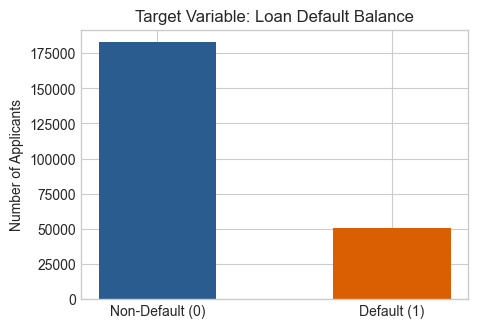

In [15]:
counts = df['loan_default'].value_counts()
pcts = df['loan_default'].value_counts(normalize=True) * 100

print(f"Non-Defaults (0): {counts[0]:,} ({pcts[0]:.1f}%)")
print(f"Defaults (1):     {counts[1]:,} ({pcts[1]:.1f}%)")

# Simple Bar Chart
plt.figure(figsize=(5, 3.5))
plt.bar(['Non-Default (0)', 'Default (1)'], counts.values, color=['#2b5c8f', '#d95f02'], width=0.5)
plt.title('Target Variable: Loan Default Balance')
plt.ylabel('Number of Applicants')
plt.show()

##### The dataset has an imbalance ratio of ~3.6 : 1 (78.3% non-defaults vs 21.7% defaults)

#### 4: Missing Value Check


In [16]:
null_counts = df.isnull().sum()
missing = null_counts[null_counts > 0]

print("Columns with Missing Values:")
print(missing)
print(f"\nMissing % in Employment.Type: {(missing['Employment.Type'] / len(df)) * 100:.2f}%")

Columns with Missing Values:
Employment.Type    7661
dtype: int64

Missing % in Employment.Type: 3.29%


##### Only one column (Employment.Type) has missing values—about 3.3% of the rows. In Phase 2, we can simply fill this as 'Missing' or 'Self-employed'

### 5: The 3 Key Risk Factors

### 5A: Loan-to-Value (LTV) — Borrower Equity

##### LTV measures how much loan is taken compared to the vehicle's price. Higher LTV means the customer paid almost zero down-payment.

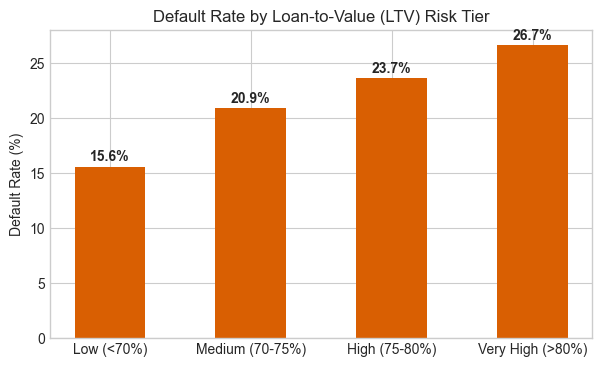

In [17]:
# Group LTV into 4 simple buckets
df['ltv_bucket'] = pd.qcut(df['ltv'], q=4, labels=['Low (<70%)', 'Medium (70-75%)', 'High (75-80%)', 'Very High (>80%)'])
ltv_risk = df.groupby('ltv_bucket', observed=False)['loan_default'].mean() * 100

plt.figure(figsize=(7, 4))
plt.bar(ltv_risk.index.astype(str), ltv_risk.values, color='#d95f02', width=0.5)
plt.title('Default Rate by Loan-to-Value (LTV) Risk Tier')
plt.ylabel('Default Rate (%)')
for i, v in enumerate(ltv_risk.values):
    plt.text(i, v + 0.5, f"{v:.1f}%", ha='center', fontweight='bold')
plt.show()

##### As LTV increases from Low to Very High, default rates jump from 15.6% to 26.7%. Borrowers with low down payments are much riskier.

### 5B: Credit Bureau Rating — Who Defaults More?

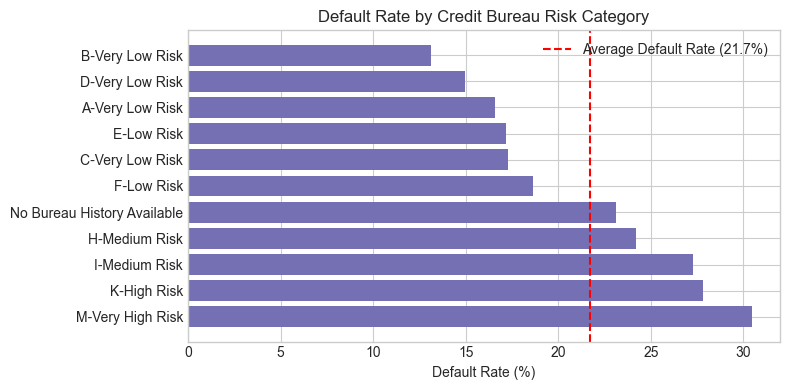

In [18]:
# Top Bureau Rating Categories vs Default Rate
bureau_risk = df.groupby('PERFORM_CNS.SCORE.DESCRIPTION')['loan_default'].agg(['count', 'mean']).sort_values('mean', ascending=False)
bureau_risk['default_rate_%'] = bureau_risk['mean'] * 100

# Plot top categories with at least 5,000 borrowers
top_bureau = bureau_risk[bureau_risk['count'] >= 5000]

plt.figure(figsize=(8, 4))
plt.barh(top_bureau.index, top_bureau['default_rate_%'], color='#7570b3')
plt.axvline(21.7, color='red', linestyle='--', label='Average Default Rate (21.7%)')
plt.title('Default Rate by Credit Bureau Risk Category')
plt.xlabel('Default Rate (%)')
plt.legend()
plt.tight_layout()
plt.show()